# Sampling the posterior of the engine's scalars: one fold run live, its chain, its autocorrelation time and what a short run can and cannot say

**Question:** What does the sampler of the Bayesian calibration do on one held-out survey when it is run live with a short chain, how long is its autocorrelation time, and what can a chain that short say about the scalars that the committed document reports?

- **Level:** 2, the method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 60 minutes (the two live runs take two to three minutes together)

## Objectives

By the end of this notebook you can:

- state the likelihood of the calibration, with the discrepancy integrated out, and say what the sampler explores and what it draws afterwards;
- run the pipeline's sampler live on one fold and read its diagnostics: acceptance, integrated autocorrelation time and the chain length measured in autocorrelation times;
- draw the chains of two parameters and say what a trace that has not forgotten its start looks like;
- say which numbers of this notebook are live and short and which are the committed full-length ones, and why the first cannot replace the second.

## Setup

Numpy and matplotlib, and `emcee` (Foreman-Mackey et al., 2013), the ensemble sampler that the pipeline's CrusherBayes module calls. The notebook does not call it directly; the pin is here because the live runs need it installed.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 emcee==3.1.6
```

The imports bring the survey reader, the CrusherBayes module (its configuration, priors and fold runner), the CrusherCal functions and the engine.

In [1]:

# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'emcee'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import crusherbayes as cb, loo
from pipeline.model.crusher import evaluate, operating_from_survey
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2
emcee 3.1.6


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`, and `data/derived/hp500/crusherbayes.json`, the document the offline bake wrote with the full-length chains; it is read here only to say which numbers are committed.

The cell reads both files and prints the size of the committed chains.

In [2]:

# The surveys, and the committed document of the full bake, read only to say which numbers are which
surveys = read_surveys().accepted
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
tph = np.array([s.feed_tph for s in surveys])
kw = np.array([s.power_kw for s in surveys])
ops = [operating_from_survey(c, f) for c, f in zip(css, f80)]
committed = json.loads((ROOT / "data/derived/hp500/crusherbayes.json").read_text(encoding="utf-8"))
meth = committed["method"]
text = (
    'committed document: {} steps per chain, {} walkers, burn-in '
    '{}, thinning {}'
)
print(text.format(meth["steps"], meth["walkers"], meth["burn_in_steps"], meth["thin"]))


committed document: 7000 steps per chain, 20 walkers, burn-in 1000, thinning 10


## Method

**The model.** For survey $i$ and target $t$ (throughput or power) the measured value is the engine at the scalars $\theta$ plus a discrepancy that is linear in the standardized setting and feed f80, plus Gaussian noise:

$$y_{t,i} = f_t(\theta; \mathrm{CSS}_i, f_{80,i}) + d_{t0} + d_{t1} z_{\mathrm{CSS},i} + d_{t2} z_{f_{80},i} + \varepsilon_{t,i}, \qquad d_{tj} \sim N(0, \tau_t^2),\ \varepsilon \sim N(0, \sigma_t^2).$$

Because the discrepancy coefficients and the noise are Gaussian given $\theta$, they can be integrated out exactly: the residual vector $y_t - f_t(\theta)$ is then normal with covariance $\sigma_t^2 I + \tau_t^2 Z Z^{\top}$, and the sampler only explores the eight engine scalars and the two noise scales, ten dimensions. The coefficients $d$ are drawn afterwards from their exact Gaussian conditional given each retained $\theta$. The sampler is `emcee`'s ensemble of 20 walkers with differential-evolution moves (ter Braak, 2006), 80 percent of the proposals, and the snooker variant (ter Braak and Vrugt, 2008), 20 percent: a walker jumps along the difference between two other walkers, which adapts the step to the shape of the posterior and needs no gradient, as an engine called as a black box requires. An earlier choice, the affine-invariant stretch move of Goodman and Weare (2010), left the autocorrelation time above 100 steps and growing, and no posterior reached the diagnostic; the differential-evolution moves are what made the committed chains converge.

**Running one fold.** A fold holds one survey out: the posterior is fitted on the other nine and the held-out survey enters only the prediction, a draw from the engine at each retained $\theta$ plus the discrepancy and the noise. The committed document runs 7000 steps per chain for each of the ten folds and for the all-ten fit. A notebook cannot afford that, so the cell runs one fold, survey 4, with 200 steps, 60 of them burn-in, through the same function the bake uses (`fit_inline`); the diagnostics it prints are the sampler's own.

In [3]:

# One fold live: survey 4 held out (index 3), a reduced chain, the pipeline's own sampler
HELD = 3
spec = {"css": css.tolist(), "f80": f80.tolist(), "tph": tph.tolist(), "kW": kw.tolist(), "held": HELD, "seed": 42}
live_cfg = cb.Config(walkers=20, steps=200, burn=60, thin=4, draws=10)
fold = cb.fit_inline(dict(spec, config=live_cfg.__dict__))
print(f"live fold, {live_cfg.steps} steps ({fold['post_burn_steps']} after burn-in): "
      f"converged {fold['converged']}, tau {fold['tau_max']:.1f} steps, "
      f"chain over tau {fold['ratio']:.1f}, acceptance {fold['acceptance']:.2f}")
for name, y in (("tph", tph), ("kW", kw)):
    p = fold["pred"][name]
    print(f"{name:5s} live mean {p['mean']:7.1f}, 80 % interval {p['lo80']:7.1f} to {p['hi80']:7.1f}, "
          f"measured {y[HELD]:7.1f}")


live fold, 200 steps (140 after burn-in): converged False, tau 11.8 steps, chain over tau 11.8, acceptance 0.28
tph   live mean  1194.1, 80 % interval   992.8 to  1388.0, measured  1034.0
kW    live mean   273.5, 80 % interval   235.3 to   312.7, measured   349.0


The live chain is short on purpose: 200 steps, 60 of them burn-in, against 7000 and 1000 in the committed document. Its own diagnostic reads an autocorrelation time of 11.8 steps, so its 140 post-burn-in steps are 11.8 autocorrelation times by its own count, under the 50 the pipeline requires, and the run reports itself as not converged. Its predictive interval for survey 4 is nevertheless in the neighbourhood of the committed one. The next cell prints the committed fold of the same survey and measures the live chain against the committed autocorrelation time, which is what says whether the live estimate of 11.8 steps can be believed.

In [4]:

# The committed fold of the same survey, run for the full length, beside the live one
folds = {c["fold"]: c for c in committed["convergence"]["folds"]}
doc = folds[HELD + 1]
print(f"committed fold: converged {doc['converged']}, tau {doc['tau_max']:.1f} steps, "
      f"chain over tau {doc['chain_over_tau']:.1f}, acceptance {doc['acceptance_fraction']:.2f}")
for name in ("tph", "kW"):
    block = committed["loo"][name]
    print(f"{name:5s} committed mean {block['pred_mean'][HELD]:7.1f}, 80 % interval {block['lo80'][HELD]:7.1f} to "
          f"{block['hi80'][HELD]:7.1f}")
# The live autocorrelation time against the committed one, and the live chain in committed taus
print(f"committed tau over live tau: {doc['tau_max'] / fold['tau_max']:.1f}; "
      "the live post-burn-in chain is "
      f"{fold['post_burn_steps'] / doc['tau_max']:.1f} committed autocorrelation times long")


committed fold: converged True, tau 84.8 steps, chain over tau 70.7, acceptance 0.17
tph   committed mean  1195.2, 80 % interval   999.5 to  1388.2
kW    committed mean   271.4, 80 % interval   233.7 to   310.1
committed tau over live tau: 7.2; the live post-burn-in chain is 1.7 committed autocorrelation times long


Committed, the fold of survey 4 has an autocorrelation time of 84.8 steps, 7.2 times the 11.8 steps the live chain measured for itself, and a chain of 70.7 times that, above the 50 the pipeline asks for: 11 of the 11 committed posteriors pass the diagnostic, with chain over tau between 70.7 and 125.0. Measured in the committed autocorrelation time, the 140 post-burn-in steps of the live run are 1.7 autocorrelation times long, not 11.8. A short chain underestimates its own autocorrelation time, because it has not run long enough to see how slowly it decorrelates, and so it flatters its own diagnostic. Survey 4 is the slowest of the ten folds, so it is the demanding case for a live run, and the committed diagnostic is the figure to trust.

**The chains.** To see the chains themselves the notebook needs the retained samples, which the pipeline returns for the fit to all ten surveys, not for a fold, so the next cell runs that fit briefly (120 steps), keeps its samples and measures it against the committed all-ten posterior in the same way.

In [5]:

# The posterior from all ten surveys, live and short, to see the chain of the scalars
all_cfg = cb.Config(walkers=20, steps=120, burn=40, thin=2, draws=10)
every = cb.fit_inline(dict(spec, held=None, config=all_cfg.__dict__))
chain = np.array(every["theta"])
print(f"live all-ten run, {all_cfg.steps} steps: tau {every['tau_max']:.1f} steps, "
      f"chain over tau {every['ratio']:.1f}, {chain.shape[0]} retained samples")
# The same live chain measured in the committed autocorrelation time of the all-ten posterior
print(f"committed all-ten tau: {folds['all']['tau_max']:.1f} steps; "
      "the live post-burn-in chain is "
      f"{every['post_burn_steps'] / folds['all']['tau_max']:.1f} committed autocorrelation times long")


live all-ten run, 120 steps: tau 7.9 steps, chain over tau 10.2, 800 retained samples
committed all-ten tau: 48.6 steps; the live post-burn-in chain is 1.6 committed autocorrelation times long


The all-ten run tells the same story: 10.2 autocorrelation times by its own count and 1.6 in the committed one. The retained samples come back flat, step after step with the 20 walkers of each step together; the cell reorders them by step, walker and parameter.

In [6]:

# Reshape the retained samples into steps by walkers by parameters, to draw the chains
walkers = all_cfg.walkers
steps_kept = chain.shape[0] // walkers
chains = chain.reshape(steps_kept, walkers, -1)
print(chains.shape)


(40, 20, 10)


The figure draws five of the 20 walkers for the capacity base and for the power noise scale, in the retained order after burn-in.

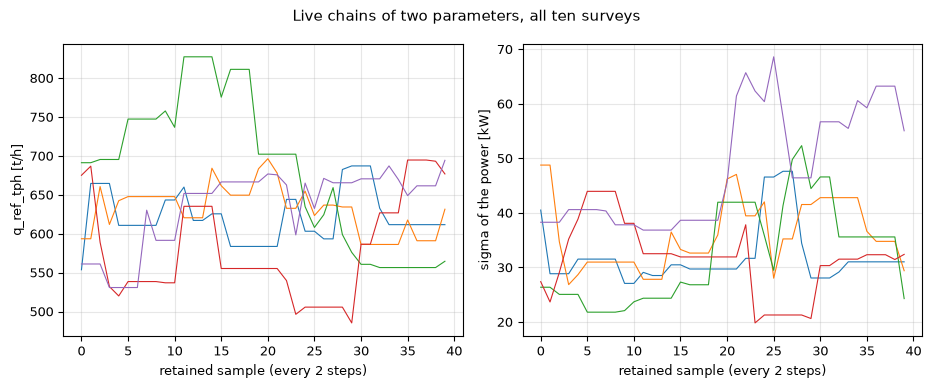

In [7]:

# The chains of the capacity base and of the power noise, five walkers, after the burn-in
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
panels = (
    (axes[0], 0, np.exp, 'q_ref_tph [t/h]'),
    (axes[1], cb.N_ENGINE + 1, np.exp, 'sigma of the power [kW]'),
)
for ax, column, transform, ylabel in panels:
    for w in range(5):
        ax.plot(transform(chains[:, w, column]), lw=0.8)
    ax.set_xlabel('retained sample (every {} steps)'.format(all_cfg.thin))
    ax.set_ylabel(ylabel)
fig.suptitle('Live chains of two parameters, all ten surveys')
fig.tight_layout()
plt.show()


A converged chain looks like a band without drift or visible runs, in which a walker revisits every part of the band many times. These traces are a short stretch from near the prior centre, where the walkers start in a small ball: each walker still wanders slowly across a range of the size of the band, which is what a chain of under two autocorrelation times looks like. The figure does not show where the chains settle; the committed chains, 7000 steps long, are the ones that settle, and their record is below.

What the samples say about the parameters is the contraction, the posterior standard deviation over the prior one: near 1 the data did not move the parameter, well below 1 they did. The cell prints it for the eight scalars from the live chain beside the committed ratio from the full-length fit, and asks whether the two columns order the scalars the same way, with the rank correlation of the two.

In [8]:

# Posterior against prior for the live run: mean and standard deviation of each engine scalar, and
# the rank correlation of the live and the committed contraction
contraction = {c["name"]: c["contraction"] for c in committed["contraction"]}
header = ('scalar          prior mean  prior sd   live mean  live sd   '
          'live sd / prior sd   committed ratio')
print(header)
live_ratio = np.zeros(cb.N_ENGINE)
for i, p in enumerate(cb.PRIORS):
    live = np.exp(chain[:, i]) if p.log else chain[:, i]
    prior_sd = cb.prior_sd_natural(p)
    live_ratio[i] = live.std() / prior_sd
    print(f"{p.name:15s} {p.nominal:11.2f} {prior_sd:9.3f} {live.mean():11.3f} {live.std():8.3f}", end=" ")
    print(f"{live_ratio[i]:20.2f} {contraction[p.name]:18.2f}")
# Rank correlation of the two columns, over the eight scalars and without the capacity base
committed_ratio = np.array([contraction[p.name] for p in cb.PRIORS])
rank_live = np.argsort(np.argsort(live_ratio))
rank_committed = np.argsort(np.argsort(committed_ratio))
rho_all = np.corrcoef(rank_live, rank_committed)[0, 1]
rest_live = np.argsort(np.argsort(live_ratio[1:]))
rest_committed = np.argsort(np.argsort(committed_ratio[1:]))
rho_rest = np.corrcoef(rest_live, rest_committed)[0, 1]
print(f"rank correlation of the live and committed ratios: {rho_all:+.2f} over the eight scalars, "
      f"{rho_rest:+.2f} without q_ref_tph")


scalar          prior mean  prior sd   live mean  live sd   live sd / prior sd   committed ratio
q_ref_tph            647.00   167.010     627.595   65.102                 0.39               0.45
wi_kwh_t               9.00     1.516       8.076    1.077                 0.71               0.85
zeta                   1.30     0.305       1.284    0.255                 0.84               0.73
pn_kw                110.00    47.853      77.200   36.365                 0.76               0.80
k1_scale               1.00     0.152       1.057    0.111                 0.73               0.96
k2_scale               1.00     0.152       1.087    0.108                 0.71               1.03
k3                     2.30     0.489       2.139    0.297                 0.61               0.99
t10_shift_pct          0.00     3.991       2.938    2.569                 0.64               0.99
rank correlation of the live and committed ratios: -0.24 over the eight scalars, -0.86 without q_ref_tph


The figure shows the live histogram of the capacity base with its prior centre, and of the discrepancy slope on the setting for the power, with zero marked.

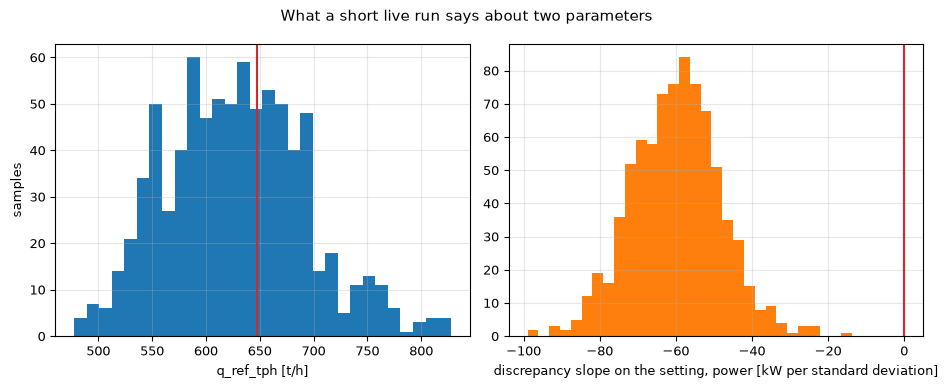

In [9]:

# Histogram of the capacity base and of one discrepancy slope in the live run, with the prior centre and zero
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
axes[0].hist(np.exp(chain[:, 0]), bins=30, color="tab:blue")
axes[0].axvline(cb.PRIORS[0].nominal, color="tab:red", lw=1.5)
axes[0].set_xlabel('q_ref_tph [t/h]')
axes[0].set_ylabel('samples')
slope = np.array(every["d_samples"]["kW"])[:, 1]
axes[1].hist(slope, bins=30, color="tab:orange")
axes[1].axvline(0.0, color="tab:red", lw=1.5)
axes[1].set_xlabel((
    'discrepancy slope on the setting, power [kW per standard '
    'deviation]'
))
fig.suptitle('What a short live run says about two parameters')
fig.tight_layout()
plt.show()


A chain this short cannot order the scalars, apart from the capacity base. The rank correlation between the live ratios and the committed ones is -0.24 over the eight scalars and -0.86 without the capacity base, both negative: `zeta` is the least contracted live (0.84) and the second most contracted in the committed fit (0.73), and `k3` is the second most contracted live (0.61) and at its prior in the committed fit (0.99). Every live ratio lies between 0.39 and 0.84, which is what walkers look like that started in a small ball around the prior centre and have not finished spreading: a live ratio below 1 reflects that start, not information from the data. Only the capacity base, the one scalar that moves the throughput (notebook 01), is the most contracted in both columns (0.39 live, 0.45 committed). The committed column, from chains that passed their diagnostic, is the one to quote: `k1_scale`, `k2_scale`, `k3` and `t10_shift_pct` stay at 0.96, 1.03, 0.99 and 0.99, which is their prior. The slope on the setting for the power is negative, with zero outside the bulk of its histogram: the discrepancy takes up the fall of the plant's power with the opening of the setting that the engine misses (notebook 01). The histograms come from the same short chain, so the sign of the slope can be read from them and their widths cannot.

**What the calibrated engine does.** The posterior mean of the scalars from the live chain can be put back in the engine, which is evaluated on the ten surveys, in sample, with the engine's own function. This is not a held-out result and is labelled so: it says what the scalars alone, without the discrepancy, achieve.

In [10]:

# The engine at the live posterior mean of the scalars, on the ten surveys, in sample
theta_mean = chain.mean(axis=0)
calibrated = [evaluate(op, cb.scalars_of(theta_mean)) for op in ops]
cal_tph = np.array([r.throughput_tph for r in calibrated])
cal_kw = np.array([r.power_kw for r in calibrated])


The shipped engine is evaluated the same way, and the cell prints the in-sample error of both on the two targets.

In [11]:

# The shipped engine on the same surveys, and the two engines' in-sample error side by side
shipped = [evaluate(op) for op in ops]
ship_tph = np.array([r.throughput_tph for r in shipped])
ship_kw = np.array([r.power_kw for r in shipped])
text = (
    'posterior-mean engine in sample: MAPE {:.2f} % on the '
    'throughput and {:.2f} % on the power; shipped {:.2f} % and '
    '{:.2f} %'
)
print(text.format(loo.mape(tph, cal_tph), loo.mape(kw, cal_kw),
                  loo.mape(tph, ship_tph), loo.mape(kw, ship_kw)))


posterior-mean engine in sample: MAPE 12.55 % on the throughput and 24.43 % on the power; shipped 11.55 % and 47.58 %


In sample, the engine at the live posterior mean has a power MAPE of 24.43 percent against 47.58 for the shipped engine, about half, and a throughput MAPE of 12.55 percent against 11.55, slightly worse: the scalars remove most of the power offset and give up a little throughput accuracy for it. The band that CrusherCal gives a model from its residuals, `loo.predictive_band`, can be put around each of the two engines' power residuals, to compare how much scatter each leaves.

In [12]:

# The in-sample 80 percent band of the calibrated engine's power residuals, with CrusherCal's function
cal_band = loo.predictive_band(kw - cal_kw)
ship_band = loo.predictive_band(kw - ship_kw)
text = (
    'calibrated engine, power: sigma {:.1f} kW, half-width {:.1f} '
    'kW; shipped engine: sigma {:.1f} kW, half-width {:.1f} kW'
)
print(text.format(cal_band["sigma"], cal_band["halfwidth"], ship_band["sigma"], ship_band["halfwidth"]))


calibrated engine, power: sigma 71.6 kW, half-width 91.8 kW; shipped engine: sigma 73.5 kW, half-width 94.2 kW


The scalars barely change the scatter: the sigma of the power residuals is 71.6 kW for the calibrated engine against 73.5 kW for the shipped one, so what the calibration removed is the offset and not the spread around it. The same residuals can be given CrusherCal's nested coverage, in which each survey's band is sized by the other nine, to see whether the calibration changes it.

In [13]:

# The nested coverage of the two engines' power residuals, each survey's sigma taken from the other
# nine
cal_nested = loo.nested_band_coverage(kw - cal_kw)
ship_nested = loo.nested_band_coverage(kw - ship_kw)
text = (
    'nested 80 % coverage of the power: calibrated engine {:.2f}, '
    'shipped engine {:.2f}'
)
print(text.format(cal_nested["coverage"], ship_nested["coverage"]))


nested 80 % coverage of the power: calibrated engine 0.70, shipped engine 0.60


The nested coverage of the power is 0.70 for the calibrated engine and 0.60 for the shipped one, against the nominal 0.80. With ten surveys one survey moves a coverage by 0.1, so the calibrated engine is one survey short of the nominal value and the shipped one two: the calibration adds one covered survey. The shortfall is the offset and not the width: each band is sized from the spread of the residuals about their own mean but is centred on zero, so the surveys it misses are the ones the offset pushes out. Last, the engine can be run at retained posterior draws and not only at their mean: the spread of the power across the draws is the part of the uncertainty that the scalars carry, before the discrepancy and the noise.

In [14]:

# The engine at 40 retained posterior draws of the scalars: how far the posterior moves the power of
# each survey
rows = chain[:: max(1, chain.shape[0] // 40)][:40]
spread = np.array([[evaluate(op, cb.scalars_of(theta)).power_kw for op in ops] for theta in rows])
text = (
    '{} draws: mean standard deviation of the power across draws '
    '{:.1f} kW, largest over the surveys {:.1f} kW'
)
print(text.format(len(rows), spread.std(axis=0).mean(), spread.std(axis=0).max()))


40 draws: mean standard deviation of the power across draws 16.9 kW, largest over the surveys 18.3 kW


Across 40 posterior draws the power of a survey moves by 16.9 kW on average and 18.3 kW at most, about a quarter of the 71.6 kW residual sigma, and a lower figure, since it comes from a chain that has not finished spreading: the uncertainty the scalars carry is small beside the scatter they leave. All of these numbers are in sample, so they flatter the calibrated engine. Together they are the case for the discrepancy: the scalars remove the offset, halving the power MAPE, and leave the scatter almost unchanged, which is the part a function of the setting and the feed has to carry. The held-out comparison with the discrepancy included, on all ten folds, is the subject of the next notebook.

## Results

**Answer:** a notebook-sized chain shows how the sampler works but cannot replace the committed one, which does converge. The live fold of survey 4 ran 200 steps and measured its own autocorrelation time as 11.8 steps, which makes its chain 11.8 autocorrelation times long by its own count, short of the 50 the pipeline requires. The committed fold of the same survey, 7000 steps, has an autocorrelation time of 84.8 steps, 7.2 times the live estimate, so the live chain is really 1.7 autocorrelation times long: a short chain flatters its own diagnostic. The committed chain is 70.7 times its autocorrelation time, and all 11 of the 11 committed posteriors pass, from 70.7 to 125.0 times. Nor can a short chain order the parameters by how much the data move them: its contraction ratios do not rank the scalars as the committed ones do (rank correlation -0.24 over the eight scalars, -0.86 without the capacity base), because its walkers have not finished spreading. What it shows is the mechanism; the contraction (the capacity base at 0.45 of its prior, `k1_scale`, `k2_scale`, `k3` and `t10_shift_pct` at 0.96 to 1.03) and the predictive intervals are read from the committed document, and the notebook says which numbers are live.

## Summary

The calibration is an ensemble sampler over ten dimensions around a black-box engine, with the discrepancy integrated out exactly. Run live on one fold it shows how the machinery works and how long the chain of this problem is in autocorrelation times, and that a short chain's own estimate of that length cannot be trusted; it also shows why the diagnostic exists, since a short chain looks plausible before it has converged. The next notebook leaves the sampling and measures the claim the method makes on all ten surveys held out, including where it does not win.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- ter Braak, C. J. F. (2006), A Markov chain Monte Carlo version of the genetic algorithm differential evolution: easy Bayesian computing for real parameter spaces, Statistics and Computing 16, 239-249. https://doi.org/10.1007/s11222-006-8769-1
- ter Braak, C. J. F., Vrugt, J. A. (2008), Differential evolution Markov chain with snooker updater and fewer chains, Statistics and Computing 18, 435-446. https://doi.org/10.1007/s11222-008-9104-9
- Goodman, J., Weare, J. (2010), Ensemble samplers with affine invariance, Communications in Applied Mathematics and Computational Science 5(1), 65-80. https://doi.org/10.2140/camcos.2010.5.65
- Foreman-Mackey, D., Hogg, D. W., Lang, D., Goodman, J. (2013), emcee: The MCMC Hammer, Publications of the Astronomical Society of the Pacific 125(925), 306-312. https://doi.org/10.1086/670067